# 03. Modeling and Evaluation
We train regression models to predict `SalePrice` and compare them with 5-fold cross-validation.

Metrics: **RMSE** and **MAE** in dollars (MAE is less sensitive to outliers), plus **RMSE on log(price)**, the standard Kaggle metric for this dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

## 1. Load Data
Only the houses from the training set have a price, so we keep the cleaned rows that also appear in `y_train`.

In [2]:
X = pd.read_csv('../data/processed/X_clean.csv', index_col='Id')
y = pd.read_csv('../data/processed/y_train.csv', index_col='Id')['SalePrice']

X = X.loc[X.index.intersection(y.index)].astype(float)
y = y.loc[X.index]
y_log = np.log1p(y)  # prices are right-skewed, the log makes the target closer to normal

print(f'X shape: {X.shape}, y shape: {y.shape}')

X shape: (1376, 154), y shape: (1376,)


## 2. Models
From a simple baseline (predicting the mean price) to tree ensembles.

In [3]:
models = {
    'Baseline (mean)': DummyRegressor(),
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
    'Random Forest': RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=800, learning_rate=0.03, max_depth=3,
                                                   subsample=0.8, random_state=42),
}

## 3. Cross-Validation
Every house gets a prediction from a model that did not see it during training.

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
results, preds = [], {}

for name, model in models.items():
    p_log = cross_val_predict(model, X, y_log, cv=cv)
    p = np.expm1(p_log)
    preds[name] = p
    results.append({
        'Model': name,
        'RMSE ($)': np.sqrt(mean_squared_error(y, p)),
        'MAE ($)': mean_absolute_error(y, p),
        'RMSE (log)': np.sqrt(mean_squared_error(y_log, p_log)),
    })

results = pd.DataFrame(results).set_index('Model').sort_values('RMSE (log)')
results.round(3)

,RMSE ($),MAE ($),RMSE (log)
Model,,,
Gradient Boosting,26528.496,14808.420,0.118
Random Forest,30920.951,17964.326,0.139
Ridge,46046.793,17171.923,0.141
Linear Regression,49906.469,17877.258,0.145
Baseline (mean),80202.800,55224.918,0.380


## 4. Best Model: Predicted vs Actual

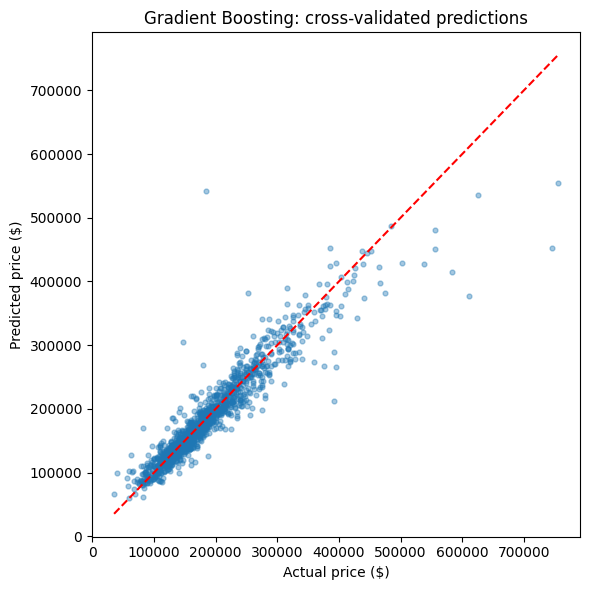

In [5]:
best = results.index[0]
plt.figure(figsize=(6, 6))
plt.scatter(y, preds[best], alpha=0.4, s=12)
lim = [y.min(), y.max()]
plt.plot(lim, lim, 'r--')
plt.xlabel('Actual price ($)')
plt.ylabel('Predicted price ($)')
plt.title(f'{best}: cross-validated predictions')
plt.tight_layout()
plt.savefig('../predicted_vs_actual.png', dpi=120)
plt.show()

## 5. Most Important Features

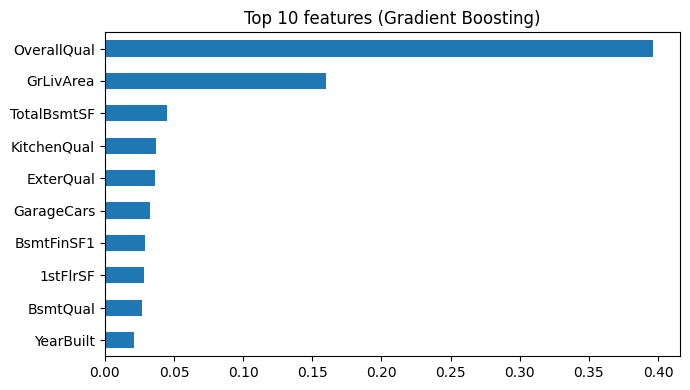

OverallQual    0.396
GrLivArea      0.160
TotalBsmtSF    0.045
KitchenQual    0.037
ExterQual      0.036
GarageCars     0.032
BsmtFinSF1     0.029
1stFlrSF       0.028
BsmtQual       0.027
YearBuilt      0.021
dtype: float64

In [6]:
gb = models['Gradient Boosting'].fit(X, y_log)
importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(10).iloc[::-1].plot.barh(figsize=(7, 4), title='Top 10 features (Gradient Boosting)')
plt.tight_layout()
plt.show()
importance.head(10).round(3)

## 6. Conclusions
- **Gradient Boosting** is the best model: RMSE(log) **0.118**, MAE about **$14.8k** — a 73% lower MAE than the mean baseline.
- Tree ensembles beat linear models, but Ridge is close on MAE, so most of the signal is roughly linear in the engineered features.
- The most important features are overall quality, living area and basement size, which matches domain intuition.